# Regime Structure 06 — delta-hedged long 0DTE straddle (gamma scalping)

Pre-registration: `discussions/Regime_Structure/011_claude_rs06_preregistration.md`. Code: `src/data_engineering/modeling/gamma_scalp.py`. Ivan lifted the no-hedging constraint for this test.

- **Option leg** (VRP 02 code): long ATM 0DTE straddle at the ask + fee, every full hour with 2–20 h to the 08:00 UTC expiry, settled at the delivery price.
- **Hedge leg:** Deribit perpetual on the 5-minute collector grid, delta from Black-76 at the entry straddle IV, rebalanced every $H$ minutes, closed at the last bar before expiry. Cost per side: half the quoted spread + taker fee 0.05%.
- **Primary:** $H$ = 15 min, taker. VRP 02 statistic and verdict. Reported: $H\in\{5,15,30,60\}$, fee scenarios, hedged − unhedged, realised-at-$H$ / implied variance.
- **Section 4 (descriptive, Binance 2 years):** variance ratio by sampling interval — microstructure noise vs genuine intraday reversion.

Environment: `RS06_ASSETS`, `RS06_OFFLINE=1`, `RS06_SYNTHETIC=1`.

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import gamma_scalp as gs, vrp_long_straddle as ls, big_move_days as bm
gs, ls, bm = importlib.reload(gs), importlib.reload(ls), importlib.reload(bm)
SYNTHETIC = os.getenv('RS06_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('RS06_ASSETS', 'BTC,ETH,SOL,XRP').split(',') if a.strip()]
P = gs.Params()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='rs06_')); DATA_ROOT = BIN_DIR = None
else:
    DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or DATA_ROOT.parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Regime_Structure' / '06'
OUT.mkdir(parents=True, exist_ok=True)
print('RS 06 |', gs.VERSION, '| VRP', ls.VERSION, '| synthetic' if SYNTHETIC else '', '| out', OUT)

RS 06 | gamma_scalp v1.0 | VRP 0.1.0  | out D:\Projects\deribit_market_data\notebooks\Regime_Structure\06


## 1. Straddles (VRP 02) and perpetual hedge paths

In [2]:
if SYNTHETIC:
    xs, tss = zip(*[gs.synthetic_sessions(25, vol=0.6, iv=0.65, reversion=0.2, half_spread=0.1, seed=90 + i, under=a)
                    for i, a in enumerate(ASSETS)])
    x = pd.concat(xs, ignore_index=True); ts = pd.concat(tss, ignore_index=True)
else:
    import duckdb
    con = duckdb.connect(str(DATA_ROOT / 'database' / 'research.duckdb'), read_only=True)
    try:
        have = set(con.execute('DESCRIBE normalized_option_chain').df()['column_name'])
        cols = [c for c in ls.CHAIN_COLUMNS if c != 'settlement_currency'] + (['settlement_currency'] if 'settlement_currency' in have else [])
        chain = con.execute(f'''
            WITH prim AS (SELECT DISTINCT state_id, option_family_id FROM primary_option_surface_feature_state)
            SELECT {', '.join('n.' + c for c in cols)}
            FROM normalized_option_chain n
            JOIN prim p ON p.state_id = n.state_id AND p.option_family_id = n.option_family_id
            WHERE n.minutes_to_expiry BETWEEN {ls.MIN_TTE_MIN} AND {ls.MAX_TTE_MIN}
              AND EXTRACT(minute FROM n.state_time) = 0
              AND n.state_time < TIMESTAMPTZ '{ls.VRP_CONFIRMATION_START.isoformat()}'
              AND abs(ln(n.strike / n.option_forward_price)) < 0.05
              AND n.underlying IN ({','.join(repr(a) for a in ASSETS)})
        ''').df()
        tcols = set(con.execute('DESCRIBE time_series_feature_state').df()['column_name'])
        want = [c for c in ('futures_index_price', 'futures_tradable_mid_price', 'futures_spread_bps') if c in tcols]
        print('hedge-path columns available:', want)
        ts = con.execute(f'''SELECT state_time, underlying, {', '.join(want)} FROM time_series_feature_state
                             WHERE state_time < TIMESTAMPTZ '{(ls.VRP_CONFIRMATION_START + pd.Timedelta(hours=8)).isoformat()}'
                               AND underlying IN ({','.join(repr(a) for a in ASSETS)})''').df()
    finally:
        con.close()
    if 'settlement_currency' not in chain:
        chain['settlement_currency'] = None
    st = ls.select_straddles(ls.prepare_legs(chain))
    sessions = sorted(st.session.unique())
    approx = ls.approx_settlement(ts[['state_time', 'underlying', 'futures_index_price']], sessions)
    names = sorted({ls.index_name(u, c) for u, c in zip(st.underlying, st.settlement_currency)})
    cache = OUT / '06_delivery_prices.csv'
    delivery = (pd.read_csv(cache, dtype={'session': str}) if (os.getenv('RS06_OFFLINE', '').strip() == '1' and cache.exists())
                else ls.fetch_delivery_prices(names, cache_csv=cache))
    x = ls.straddle_pnl(ls.attach_settlement(st, delivery[delivery.session.isin(sessions)], approx))
PATHS = gs.price_paths(ts, P)
src = pd.concat({u: p_['src'].value_counts(normalize=True) for u, p_ in PATHS.items()}).unstack().round(3)
print('hedge price source share per asset:'); display(src)
print('median perpetual half-spread (bps):', {u: round(float(p_['hs'].median() * 1e4), 2) for u, p_ in PATHS.items()})
print(f'straddles: {len(x):,} | sessions: {x.session.nunique()} | {x.session.min()} -> {x.session.max()}')

hedge-path columns available: ['futures_index_price', 'futures_tradable_mid_price', 'futures_spread_bps']
hedge price source share per asset:


src,perp_mid,index
BTC,0.911,0.089
ETH,0.911,0.089
SOL,0.911,0.089
XRP,0.911,0.089


median perpetual half-spread (bps): {'BTC': 0.01, 'ETH': 0.02, 'SOL': 0.04, 'XRP': 0.34}
straddles: 1,673 | sessions: 23 | 2026-09-21 -> 2026-10-13


## 2. Hedge every straddle

In [3]:
t0 = time.time()
Y = gs.run(x, PATHS, P)
print(f'hedged {len(Y):,} straddles in {time.time() - t0:.0f}s; usable at H=15: {int(np.isfinite(Y.R_h15_taker).sum()):,}')
PRIM, TAB = gs.summarise(Y, P)
print('PRIMARY:', json.dumps(PRIM, default=float)); print('VERDICT:', PRIM['verdict'])
display(TAB[['metric', 'n_sessions', 'M', 'ci_low', 'ci_high', 'share_sessions_positive']].round(4))

hedged 1,673 straddles in 25s; usable at H=15: 1,610
PRIMARY: {"n_sessions": 22, "M": -0.4098730184323227, "ci_low": -0.48424733343063003, "ci_high": -0.3367570489675417, "loso_min": -0.4247716951283874, "loso_max": -0.3925036467094677, "share_sessions_positive": 0.0, "verdict": "NO_LONG_EDGE", "n_straddles": 1610, "metric": "R_h15_taker"}
VERDICT: NO_LONG_EDGE


,metric,n_sessions,M,ci_low,ci_high,share_sessions_positive
0,"R_net (unhedged, same entries)",22,-0.2782,-0.4183,-0.1240,0.1818
1,R_h5_taker,22,-0.5330,-0.6133,-0.4554,0.0000
2,R_h5_low_fee,22,-0.3311,-0.4030,-0.2591,0.0455
3,R_h5_zero_cost,22,-0.1879,-0.2591,-0.1179,0.1818
4,hedged_minus_unhedged_h5_taker,22,-0.2548,-0.3764,-0.1353,0.2727
5,rv_over_iv_h5,22,1.1957,0.9740,1.4108,1.0000
6,cost_h5_share,22,0.3451,0.3183,0.3721,1.0000
7,hpnl_h5_share,22,0.0903,-0.0450,0.2164,0.7273
8,R_h15_taker,22,-0.4099,-0.4790,-0.3386,0.0000
9,R_h15_low_fee,22,-0.2863,-0.3520,-0.2189,0.0455


## 3. By asset and by time to expiry (descriptive)

,group,n,unhedged,hedged_taker,hedged_zero_cost,rv_over_iv,hedge_cost_share
0,BTC,432,-0.2653,-0.4625,-0.1602,1.3584,0.3023
1,ETH,432,-0.2046,-0.3948,-0.1606,1.3626,0.2343
2,SOL,422,-0.3481,-0.3942,-0.2386,0.9365,0.1555
3,XRP,387,-0.3035,-0.3820,-0.2438,0.9064,0.1375
4,16-20h,348,-0.1905,-0.3475,-0.1672,1.0780,0.1800
5,2-4h,238,-0.3829,-0.4894,-0.2818,1.0651,0.2062
6,4-8h,361,-0.2835,-0.4299,-0.2139,1.2032,0.2161
7,8-16h,726,-0.2685,-0.4076,-0.1853,1.1839,0.2222


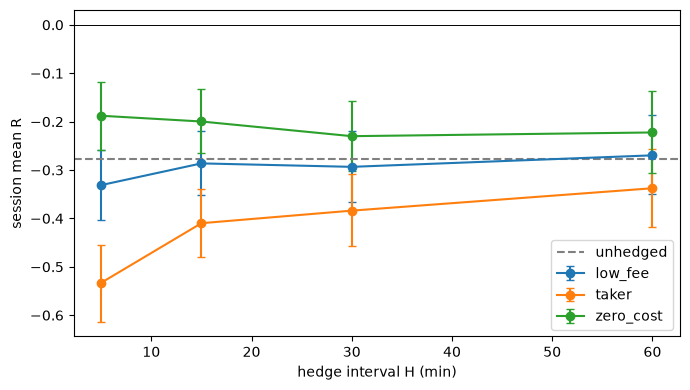

In [4]:
c = f'R_h{P.hedge_min}_taker'
by = []
for g, d in list(Y.groupby('underlying')) + list(Y.groupby('tte_bucket')):
    by.append({'group': g, 'n': len(d), 'unhedged': ls.bootstrap_mean(ls.session_means(d, 'R_net').to_numpy(), 1000).get('M'),
               'hedged_taker': ls.bootstrap_mean(ls.session_means(d, c).to_numpy(), 1000).get('M'),
               'hedged_zero_cost': ls.bootstrap_mean(ls.session_means(d, f'R_h{P.hedge_min}_zero_cost').to_numpy(), 1000).get('M'),
               'rv_over_iv': float(d[f'rv_over_iv_h{P.hedge_min}'].mean()), 'hedge_cost_share': float(d[f'cost_h{P.hedge_min}_share'].mean())})
BY = pd.DataFrame(by); display(BY.round(4))
g = TAB[TAB.metric.str.match(r'R_h\d+_')].copy()
g['H'] = g.metric.str.extract(r'R_h(\d+)_')[0].astype(int); g['scenario'] = g.metric.str.extract(r'R_h\d+_(.*)')[0]
fig, ax = plt.subplots(figsize=(7, 4))
for sc, d in g.groupby('scenario'):
    ax.errorbar(d.H, d.M, yerr=[d.M - d.ci_low, d.ci_high - d.M], marker='o', capsize=3, label=sc)
u = TAB[TAB.metric.str.startswith('R_net')].iloc[0]
ax.axhline(u.M, color='grey', ls='--', label='unhedged'); ax.axhline(0, color='k', lw=0.7)
ax.set_xlabel('hedge interval H (min)'); ax.set_ylabel('session mean R'); ax.legend(); plt.tight_layout(); plt.show()

## 4. Variance ratio by sampling interval — noise vs reversion (Binance, 2 years, descriptive)

In [5]:
VR = []
for i, a in enumerate(ASSETS):
    if SYNTHETIC:
        df = bm.synthetic_klines(n_days=400, seed=60 + i, planted=False, start='2025-06-01')
    else:
        path = BIN_DIR / f'{a}USDT_um_1m.parquet'
        if not path.exists():
            continue
        df = pd.read_parquet(path, columns=['open_time', 'close', 'volume', 'taker_buy_volume', 'trades'])
    b = bm.session_bars(df); del df
    t, _, _ = bm.session_table(b, bm.Params())
    VR.append(gs.vr_by_sampling(b['r5'], t['window'].to_numpy()).assign(asset=a))
VR = pd.concat(VR)
display(VR.pivot_table(index=['window', 'sampling_min'], columns='asset', values='vr').round(3))
print('Reading: if VR rises toward 1 as sampling gets coarser, the 5-minute reversion is mostly noise;'
      ' if it stays well below 1 at 30-60 min, the reversion is real at hedgeable horizons.')

asset                  BTC    ETH    SOL    XRP
window sampling_min                            
dev    5             0.884  1.000  0.858  0.768
       15            0.925  1.029  0.944  0.874
       30            0.935  1.032  0.955  0.872
       60            0.951  1.039  0.967  0.943
test   5             0.857  0.934  0.781  0.933
       15            0.871  0.945  0.811  0.987
       30            0.856  0.940  0.833  0.972
       60            0.862  0.929  0.849  0.969

Reading: if VR rises toward 1 as sampling gets coarser, the 5-minute reversion is mostly noise; if it stays well below 1 at 30-60 min, the reversion is real at hedgeable horizons.


## 5. Save

In [6]:
keep = ['session', 'underlying', 'state_time', 'tte_bucket', 'R_net'] + [c for c in Y.columns if c.startswith(('R_h', 'rv_over_iv', 'cost_h', 'hpnl_h'))]
Y[keep].to_csv(OUT / '06_straddles.csv', index=False, float_format='%.6g')
TAB.to_csv(OUT / '06_summary.csv', index=False)
BY.to_csv(OUT / '06_by_group.csv', index=False)
VR.to_csv(OUT / '06_vr_by_sampling.csv', index=False)
(OUT / '06_manifest.json').write_text(json.dumps({'registration': gs.registration(P), 'synthetic': SYNTHETIC,
    'primary': PRIM, 'sessions': [str(Y.session.min()), str(Y.session.max())],
    'run_utc': str(pd.Timestamp.now(tz='UTC'))}, indent=2, default=str), encoding='utf-8')
print('saved', sorted(p.name for p in OUT.iterdir()))

saved ['06_by_group.csv', '06_delivery_prices.csv', '06_manifest.json', '06_straddles.csv', '06_summary.csv', '06_vr_by_sampling.csv']
